# NB08 — Confirmatory dates and blind candidate characterization
Implements **MVP3_Phase3_frozen_protocol.md** — Sentinel-2 × CBERS-4A/WPM (primary) and GCOM-C/SGLI (secondary) on the same dates. All analysis runs through `nb07_core.py` (frozen, verbatim from NB07 `_final`);
`nb08_confirm.py` only selects dates, orchestrates, guards memory and runs the pre-declared tests.

**Before the first run:** upload both `.py` files to `Marine_Plastic_Detection/code/` on Drive, and timestamp the protocol (§7).

**Every cell is resumable.** After a crash, a `MemoryError` from the guard, or a runtime restart: run cells 1–2 again, then re-run the cell that stopped.
Finished steps are cached on Drive; `confirm_log.json` records every date and decision.

*Outputs describe floating marine-debris/macroplastic aggregation candidates — no ground truth of material identity.*

## 1 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)
!pip install -q pystac_client rasterio psutil

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 3.8 MB/s eta 0:00:00


In [2]:
import sys, os, shutil, hashlib, importlib
BASE = "/content/drive/MyDrive/Marine_Plastic_Detection"
EXPECTED = {
 "nb07_core.py": "0c566d8886d499a13e34a3cb76cb86cc6671c233c27ba03dc2429208cf1027ce",
 "nb08_confirm.py": "aa29ef6915693a68bb5448ef65790587ab29dad09271fcfd9ae0a1624f89a64a"
}   # frozen: must match the protocol §7
os.makedirs("/content/code", exist_ok=True)
for f, h in EXPECTED.items():
    shutil.copy(f"{BASE}/code/{f}", f"/content/code/{f}")
    got = hashlib.sha256(open(f"/content/code/{f}", "rb").read()).hexdigest()
    assert got == h, f"{f} differs from the frozen version ({got[:12]} != {h[:12]}) — log a deviation before running"
sys.path.insert(0, "/content/code")
import nb07_core as core, nb08_confirm as cf
core.init_ee()
cf.record_hashes([f"/content/code/{f}" for f in EXPECTED])
print("frozen code verified; log:", cf.LOG_PATH)

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


[EE] Initialized on project: marplastdetection
  nb07_core.py: 0c566d8886d499a13e34a3cb76cb86cc6671c233c27ba03dc2429208cf1027ce
  nb08_confirm.py: aa29ef6915693a68bb5448ef65790587ab29dad09271fcfd9ae0a1624f89a64a
frozen code verified; log: /content/drive/MyDrive/Marine_Plastic_Detection/results/phase3_confirmatory/confirm_log.json


In [4]:
import datetime
log = cf.load_log()
log.setdefault("deviations", []).append(dict(
    id="D1", when_utc=datetime.datetime.utcnow().isoformat(),
    old_hashes=log["hashes"],
    new_hashes={"nb07_core.py": "0c566d8886d499a13e34a3cb76cb86cc6671c233c27ba03dc2429208cf1027ce",
                "nb08_confirm.py": "aa29ef6915693a68bb5448ef65790587ab29dad09271fcfd9ae0a1624f89a64a"},
    what=("nb07_core.py: added load_sgli_bsi_grid (verbatim from NB07 _final Archive; SGLI leg, protocol 4b). "
          "nb08_confirm.py: added SGLI leg and E6 (one S2 date per CBERS scene)."),
    why="SGLI added as secondary sensor on the same dates; scouting showed S2 dates sharing a CBERS pass",
    data_seen="metadata only (dates, cloud %, scene IDs); no pixels, FDI, AUC or SGLI values",
    scouting_unaffected="scout() and pair_dates() are identical in old and new nb08_confirm.py"))
log["hashes"] = None
cf._save_json(cf.LOG_PATH, log)
print("deviation D1 logged")

deviation D1 logged


/tmp/ipykernel_616/1547214037.py:4: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  id="D1", when_utc=datetime.datetime.utcnow().isoformat(),


## 2 · Scout — E1 (CBERS within ±1 day) and E2 (mean cloud ≤ 30%)
Metadata only; no pixels are read. Runs once; later runs reuse the logged result.

In [5]:
cf.scout()

[00:23:55] [scout] already done — using logged result (delete confirm_log.json only via a logged deviation)
[status] {'excluded': 444, 'confirmed': 5} | independent confirmed: ['2023-05-03', '2024-08-15', '2025-03-13', '2025-06-16', '2025-12-23'] | shared-scene (sensitivity only): []


{'excluded': 444, 'confirmed': 5}

## 3 · Process dates — E3 (≥ 11 M water px), E4 (≥ 50% candidates CBERS-valid), frozen pipeline, E5
Chronological; stops at 8 confirmed dates or when the queue ends. ~25–30 min of Earth Engine time per date that passes E3/E4,
~12–15 min per date that fails them. Re-run this cell after any interruption: it resumes from the log.
`max_dates` limits one session's work (e.g. `cf.run(max_dates=2)`), so long queues can be split across sessions.

In [6]:
cf.run()

[00:24:04] [stop] window exhausted: 5 confirmed dates
[status] {'excluded': 444, 'confirmed': 5} | independent confirmed: ['2023-05-03', '2024-08-15', '2025-03-13', '2025-06-16', '2025-12-23'] | shared-scene (sensitivity only): []


{'excluded': 444, 'confirmed': 5}

## 3b · SGLI leg (secondary, H-S1) — GCOM-C/SGLI L2 NWLR 1 km on the **same S2 dates**
1. Run `cf.sgli_needed()` — lists every confirmed date and the file pattern `GC1SG1_YYYYMMDD*_L2SG_NWLRK_*.h5`.
2. Download those files from JAXA G-Portal (same product as the exploratory 2024-09-09 file) into `Marine_Plastic_Detection/sgli_confirmatory/`.
   If several granules exist for a date, put all of them there; the one with most QA-valid AOI pixels is used automatically.
3. Run `cf.run_sgli()`. Re-run after adding files. SGLI availability never changes which dates are in the S2 × CBERS test.

In [7]:
cf.sgli_needed()

  2023-05-03: OK GC1SG1_202305031256A27514_L2SG_NWLRK_3001.h5
  2024-08-15: MISSING  -> GC1SG1_20240815*_L2SG_NWLRK_*.h5
  2025-03-13: MISSING  -> GC1SG1_20250313*_L2SG_NWLRK_*.h5
  2025-06-16: MISSING  -> GC1SG1_20250616*_L2SG_NWLRK_*.h5
  2025-12-23: MISSING  -> GC1SG1_20251223*_L2SG_NWLRK_*.h5


In [8]:
cf.run_sgli()

[00:25:03] [mem] 10% RAM, 12.3 GB free — SGLI GC1SG1_202305031256A27514_L2SG_NWLRK_3001.h5
[00:25:03] [SGLI-BSI] opening /content/drive/MyDrive/Marine_Plastic_Detection/sgli_confirmatory/GC1SG1_202305031256A27514_L2SG_NWLRK_3001.h5
[00:25:04] [SGLI-BSI] windowed full-res read: rows 1032:1121, cols 327:416
[00:25:04] [SGLI-BSI] windowed QA-valid pixels: 1915 of 7921 (24.2%)
[00:25:05] [mem] 10% RAM, 12.3 GB free — SGLI 2023-05-03 S2 points
[00:25:07] [S2-FDI] complete cache hit (18797266 px) -- skipping EE entirely
[S2] near-threshold (top 1%): 188036 points
[S2] background-water control: 20000 points (random, <= p50)
[00:25:09] [SGLI] 2023-05-03: GC1SG1_202305031256A27514_L2SG_NWLRK_3001.h5 | distinct px cand 166, bg 750 | LR+ 1.734426410124148 CI [0.15272794778394297, 3.9212773259079015] | evaluable=False
[00:25:09] [SGLI] 2024-08-15: no file
[00:25:09] [SGLI] 2025-03-13: no file
[00:25:09] [SGLI] 2025-06-16: no file
[00:25:09] [SGLI] 2025-12-23: no file
  2023-05-03: OK GC1SG1_202305

In [9]:
print(sorted(os.listdir(cf.SGLI_DIR)))

['GC1SG1_202305031256A27514_L2SG_NWLRK_3001.h5', 'GC1SG1_202307071235D26814_L2SG_NWLRQ_3001.h5', 'GC1SG1_202309081307H27914_L2SG_NWLRQ_3001.h5', 'GC1SG1_202402101302Q27814_L2SG_NWLRQ_3001.h5', 'GC1SG1_202406141251F27514_L2SG_NWLRQ_3002.h5', 'GC1SG1_202503131249D27514_L2SG_NWLRQ_3002.h5', 'GC1SG1_202505201250F27514_L2SG_NWLRQ_3002.h5', 'GC1SG1_202506161236D27014_L2SG_NWLRQ_3002.h5', 'GC1SG1_202506191256V27714_L2SG_NWLRQ_3002.h5']


In [10]:
import os, glob, gc, datetime as dt, numpy as np
log = cf.load_log()
if not any(x.get("id") == "D2" for x in log.get("deviations", [])):
    log.setdefault("deviations", []).append(dict(
        id="D2", when_utc=dt.datetime.now(dt.timezone.utc).isoformat(),
        what="Supplementary SGLI analysis on the 250 m NWLR product (NWLRQ); protocol 4b specifies NWLRK only",
        why="G-Portal returned NWLRQ granules for most dates; tests the open 250 m question (reasoning doc 13.7)",
        rules="identical to 4b except file code NWLRQ; confirmed S2 dates only; reported separately from registered H-S1",
        data_seen="file names only; no 250 m values read before this entry"))
    cf._save_json(cf.LOG_PATH, log)

out, C = {}, dict(cc=[], cp=[], bc=[], bp=[])
for d in sorted(k for k, r in log["dates"].items() if r["status"] == "confirmed"):
    files = sorted(glob.glob(os.path.join(cf.SGLI_DIR, f"GC1SG1_{d.replace('-', '')}*NWLRQ*.h5")))
    if not files:
        out[d] = dict(status="no_file"); continue
    best, errs = None, []
    for f in files:
        cf.mem_guard(f"SGLI-250m {os.path.basename(f)}")
        try:
            g = core.load_sgli_bsi_grid(f)
        except (AssertionError, KeyError) as e:
            errs.append(f"{os.path.basename(f)}: {e!r}"[:200]); continue
        if best is None or len(g[2]) > len(best[1][2]):
            best = (os.path.basename(f), g)
        del g; gc.collect()
    if best is None:
        out[d] = dict(status="no_valid_pixels", errors=errs); continue
    fname, (lat, lon, bsi) = best
    thr = float(np.percentile(bsi, cf.SGLI_PCT))
    slon, slat, sfdi = core.get_s2_fdi_array(d)
    near, bg = core.build_near_threshold_and_background(np.asarray(slon), np.asarray(slat), np.asarray(sfdi))
    del slon, slat, sfdi; gc.collect()
    res = core.analyze_sgli(lat, lon, bsi, thr, near[:, :2], bg[:, :2], core.SGLI_MATCH_TOLERANCE_M)
    cc, cp = cf._sgli_clusters(lat, lon, bsi, thr, near[:, :2]); bc, bp = cf._sgli_clusters(lat, lon, bsi, thr, bg[:, :2])
    C["cc"] += cc.tolist(); C["cp"] += cp.astype(int).tolist(); C["bc"] += bc.tolist(); C["bp"] += bp.astype(int).tolist()
    out[d] = dict(status="done", file=fname, n_valid_px=int(len(bsi)), threshold_p90=thr, result=res, errors=errs)
    del near, bg, lat, lon, bsi; gc.collect()
    print(f"[SGLI-250m] {d}: {fname} | distinct px cand {res.get('distinct_px_cand')}, bg {res.get('distinct_px_bg')} "
          f"| LR+ {res.get('lr')} CI {res.get('cluster_bootstrap', {}).get('lr_ci')}")
pooled = cf.cluster_boot(C["cc"], C["cp"], C["bc"], C["bp"]) if C["cc"] and C["bc"] else None
cf._save_json(os.path.join(cf.OUT_DIR, "D2_sgli_250m_supplementary.json"), dict(deviation="D2", per_date=out, pooled=pooled))
print("pooled 250 m:", pooled["verdict"] if pooled else "not assessable",
      {k: pooled[k] for k in ("lr", "lr_ci", "distinct_px_cand")} if pooled else "")

[00:29:15] [mem] 10% RAM, 12.2 GB free — SGLI-250m GC1SG1_202503131249D27514_L2SG_NWLRQ_3002.h5
[00:29:15] [SGLI-BSI] opening /content/drive/MyDrive/Marine_Plastic_Detection/sgli_confirmatory/GC1SG1_202503131249D27514_L2SG_NWLRQ_3002.h5
[00:29:19] [SGLI-BSI] windowed full-res read: rows 4144:4454, cols 1397:1726
[00:29:19] [SGLI-BSI] windowed QA-valid pixels: 37093 of 101990 (36.4%)
[00:29:24] [S2-FDI] complete cache hit (19164916 px) -- skipping EE entirely
[S2] near-threshold (top 1%): 191656 points
[S2] background-water control: 20000 points (random, <= p50)
[SGLI-250m] 2025-03-13: GC1SG1_202503131249D27514_L2SG_NWLRQ_3002.h5 | distinct px cand 622, bg 8233 | LR+ 1.488106956369183 CI [0.6049988988470156, 2.645744949165019]
[00:29:26] [mem] 11% RAM, 12.2 GB free — SGLI-250m GC1SG1_202506161236D27014_L2SG_NWLRQ_3002.h5
[00:29:26] [SGLI-BSI] opening /content/drive/MyDrive/Marine_Plastic_Detection/sgli_confirmatory/GC1SG1_202506161236D27014_L2SG_NWLRQ_3002.h5
[00:29:30] [SGLI-BSI] windo

In [11]:
import os, glob, gc, datetime as dt, numpy as np
log = cf.load_log()
if not any(x.get("id") == "D3" for x in log.get("deviations", [])):
    log.setdefault("deviations", []).append(dict(
        id="D3", when_utc=dt.datetime.now(dt.timezone.utc).isoformat(),
        what="Open-water (>=500 m from SCL land) restriction applied to the SGLI leg, candidates and background",
        why="D2 showed LR+ > 1 on 2025-06-16; ~60% of top-1% candidates lie within 100 m of non-water, the zone that "
            "inflated CBERS AUC (0.81 whole scene vs 0.57 open water). Same rule as the primary S2xCBERS metric.",
        declared_after="D2 results were seen; reported as a robustness check whatever the outcome"))
    cf._save_json(cf.LOG_PATH, log)

OW = cf.core.OPEN_WATER_MIN_DIST_M if hasattr(cf.core, "OPEN_WATER_MIN_DIST_M") else 500.0
runs = {"2023-05-03": "NWLRK", "2025-03-13": "NWLRQ", "2025-06-16": "NWLRQ"}
out, C = {}, {p: dict(cc=[], cp=[], bc=[], bp=[]) for p in ("NWLRK", "NWLRQ")}
for d, prod in runs.items():
    f = sorted(glob.glob(os.path.join(cf.SGLI_DIR, f"GC1SG1_{d.replace('-', '')}*{prod}*.h5")))[0]
    cf.mem_guard(f"D3 {d}")
    lat, lon, bsi = core.load_sgli_bsi_grid(f)
    thr = float(np.percentile(bsi, cf.SGLI_PCT))                      # same per-scene threshold as D2 / 4b
    slon, slat, sfdi = core.get_s2_fdi_array(d)
    near, bg = core.build_near_threshold_and_background(np.asarray(slon), np.asarray(slat), np.asarray(sfdi))
    del slon, slat, sfdi; gc.collect()
    R = core.get_s2_raster(d)
    land = ~core.water_mask(R) & np.isin(R["SCL"], core.SCL_LAND); dl = core._dist(land); del land
    def dland(p):
        ix, iy, _ = core.to_grid_index(R, p[:, 0], p[:, 1]); return dl[iy, ix]
    n_ow, b_ow = near[dland(near[:, :2]) >= OW, :2], bg[dland(bg[:, :2]) >= OW, :2]
    del R, dl, near, bg; gc.collect()
    res = core.analyze_sgli(lat, lon, bsi, thr, n_ow, b_ow, core.SGLI_MATCH_TOLERANCE_M)
    cc, cp = cf._sgli_clusters(lat, lon, bsi, thr, n_ow); bc, bp = cf._sgli_clusters(lat, lon, bsi, thr, b_ow)
    for k, v in zip(("cc", "cp", "bc", "bp"), (cc.tolist(), cp.astype(int).tolist(), bc.tolist(), bp.astype(int).tolist())):
        C[prod][k] += v
    out[d] = dict(product=prod, file=os.path.basename(f), n_cand_open_water=int(len(n_ow)), n_bg_open_water=int(len(b_ow)),
                  result=res, clusters_boot=cf.cluster_boot(cc, cp, bc, bp) if len(cc) and len(bc) else None)
    print(f"[D3] {d} {prod}: open-water cand {len(n_ow)}, bg {len(b_ow)} | distinct px cand {res.get('distinct_px_cand')} "
          f"| LR+ {res.get('lr')} CI {res.get('cluster_bootstrap', {}).get('lr_ci')}")
    del lat, lon, bsi, n_ow, b_ow; gc.collect()
pooled_q = cf.cluster_boot(**{k: C["NWLRQ"][k] for k in ("cc", "cp", "bc", "bp")}) if C["NWLRQ"]["cc"] else None
cf._save_json(os.path.join(cf.OUT_DIR, "D3_sgli_open_water.json"), dict(deviation="D3", per_date=out, pooled_250m=pooled_q))
print("pooled 250 m, open water:", {k: pooled_q[k] for k in ("lr", "lr_ci", "distinct_px_cand", "verdict")} if pooled_q else "n/a")

[00:31:09] [mem] 9% RAM, 12.4 GB free — D3 2023-05-03
[00:31:09] [SGLI-BSI] opening /content/drive/MyDrive/Marine_Plastic_Detection/sgli_confirmatory/GC1SG1_202305031256A27514_L2SG_NWLRK_3001.h5
[00:31:10] [SGLI-BSI] windowed full-res read: rows 1032:1121, cols 327:416
[00:31:10] [SGLI-BSI] windowed QA-valid pixels: 1915 of 7921 (24.2%)
[00:31:12] [S2-FDI] complete cache hit (18797266 px) -- skipping EE entirely
[S2] near-threshold (top 1%): 188036 points
[S2] background-water control: 20000 points (random, <= p50)
[00:31:15] [S2-RASTER] cache hit /content/drive/MyDrive/Marine_Plastic_Detection/cache/s2_raster_2023-05-03.npz ((5210, 6367))
[D3] 2023-05-03 NWLRK: open-water cand 68036, bg 16458 | distinct px cand 121 | LR+ 0.38168260249729624 CI [0.007218410411715298, 1.133056557686885]
[00:31:21] [mem] 10% RAM, 12.3 GB free — D3 2025-03-13
[00:31:21] [SGLI-BSI] opening /content/drive/MyDrive/Marine_Plastic_Detection/sgli_confirmatory/GC1SG1_202503131249D27514_L2SG_NWLRQ_3002.h5
[00:31:

## 4 · Pre-declared tests (H-C1 primary on new dates; H-C2 pooled; sensitivities; H-S1 SGLI pooled)

In [12]:
res = cf.final_tests()

H-C1 (new dates only, n=5): rho = -0.300, p (one-sided) = 0.7417 [exact (120 permutations)] -> underpowered: descriptive only (fewer than 6 confirmatory dates)
H-S1 (SGLI, pooled over 1 dates): inconclusive | LR+ 1.73 CI [0.15, 3.92], distinct px cand 166


In [13]:
import json, os
r = json.load(open(os.path.join(cf.OUT_DIR, "confirmatory_results.json")))
f = lambda t: None if t is None else {k: (round(v, 4) if isinstance(v, float) else v) for k, v in t.items()}
print("H-C2 pooled (5 exploratory + 5 new):", f(r["H_C2_pooled_descriptive"]))
for k, v in r["sensitivity"].items():
    print(f"sens {k}: new_only={f(v['new_only'])}\n        pooled={f(v['pooled'])}")
print("shared-scene dates:", r.get("shared_scene_dates"))
for x in r["per_date_new"]:
    print(x["s2_date"], x["cbers_scene"], "own_p99", round(x["own_thr"], 4), "AUC", round(x["auc"], 3), [round(c, 3) for c in x["ci"]],
          {k: (None if v["auc"] is None else round(v["auc"], 3)) for k, v in x["sens"].items()})
print("excluded:", r["exclusion_log"])

H-C2 pooled (5 exploratory + 5 new): {'n': 10, 'spearman_rho': 0.6485, 'spearman_p_onesided': 0.0251, 'pearson_r': 0.6609, 'pearson_p_onesided': 0.0266, 'wls_slope': 0.7577, 'wls_slope_se': 0.6282, 'wls_p_twosided': 0.2622, 'permutation': 'Monte Carlo (200000 permutations, seed 0)'}
sens cut200: new_only={'n': 5, 'spearman_rho': -0.3, 'spearman_p_onesided': 0.7417, 'pearson_r': -0.4251, 'pearson_p_onesided': 0.775, 'wls_slope': 0.8719, 'wls_slope_se': 0.8931, 'wls_p_twosided': 0.4009, 'permutation': 'exact (120 permutations)'}
        pooled={'n': 10, 'spearman_rho': 0.0667, 'spearman_p_onesided': 0.434, 'pearson_r': 0.1013, 'pearson_p_onesided': 0.3453, 'wls_slope': 1.2648, 'wls_slope_se': 0.7616, 'wls_p_twosided': 0.1354, 'permutation': 'Monte Carlo (200000 permutations, seed 0)'}
sens cut1000: new_only={'n': 5, 'spearman_rho': -0.5, 'spearman_p_onesided': 0.825, 'pearson_r': -0.5993, 'pearson_p_onesided': 0.8333, 'wls_slope': 0.1281, 'wls_slope_se': 0.6728, 'wls_p_twosided': 0.8611,

In [14]:
print(json.load(open(os.path.join(cf.OUT_DIR, "confirmatory_results.json")))["H_C1_primary_new_only"])

{'n': 5, 'spearman_rho': -0.29999999999999993, 'spearman_p_onesided': 0.7416666666666667, 'pearson_r': -0.47839896393233305, 'pearson_p_onesided': 0.7833333333333333, 'wls_slope': 0.28124408245027416, 'wls_slope_se': 0.7612645723553176, 'wls_p_twosided': 0.7363342478550714, 'permutation': 'exact (120 permutations)'}


## 5 · Blind characterization — export chips and label sheets
200 points (20 candidates + 20 background × 5 exploratory dates), shuffled, anonymous IDs. Give labelers only the `chips/`
folder, `labels_labeler_A.csv` / `labels_labeler_B.csv` and `labeling_instructions.txt` — **never** the `KEY_…` folder.

In [15]:
cf.export_chips()

[00:47:28] [mem] 9% RAM, 12.4 GB free — chips 2024-09-09
[00:47:31] [S2-RASTER] cache hit /content/drive/MyDrive/Marine_Plastic_Detection/cache/s2_raster_2024-09-09.npz ((5210, 6367))
[00:47:37] [CBERS] searching STAC for 2024-09-09
[00:47:40] [CBERS] found 1 item(s) intersecting AOI: ['CBERS_4A_WPM_20240909_200_142_L4'] — a single scene may not fully cover this AOI, same issue as S2 granule boundaries
[00:47:40] [CBERS-fast] window cache hit for CBERS_4A_WPM_20240909_200_142_L4 -- skipping the 90s+ bulk read
[00:47:44] [chips] 2024-09-09: 20 candidates + 20 background sampled
[00:47:44] [mem] 10% RAM, 12.3 GB free — chips 2024-09-14
[00:47:46] [S2-RASTER] cache hit /content/drive/MyDrive/Marine_Plastic_Detection/cache/s2_raster_2024-09-14.npz ((5210, 6367))
[00:47:52] [CBERS] searching STAC for 2024-09-14
[00:47:53] [CBERS] found 1 item(s) intersecting AOI: ['CBERS_4A_WPM_20240914_199_142_L4'] — a single scene may not fully cover this AOI, same issue as S2 granule boundaries
[00:47:53

200 true-color chips | near-uniform (possible no-data): none


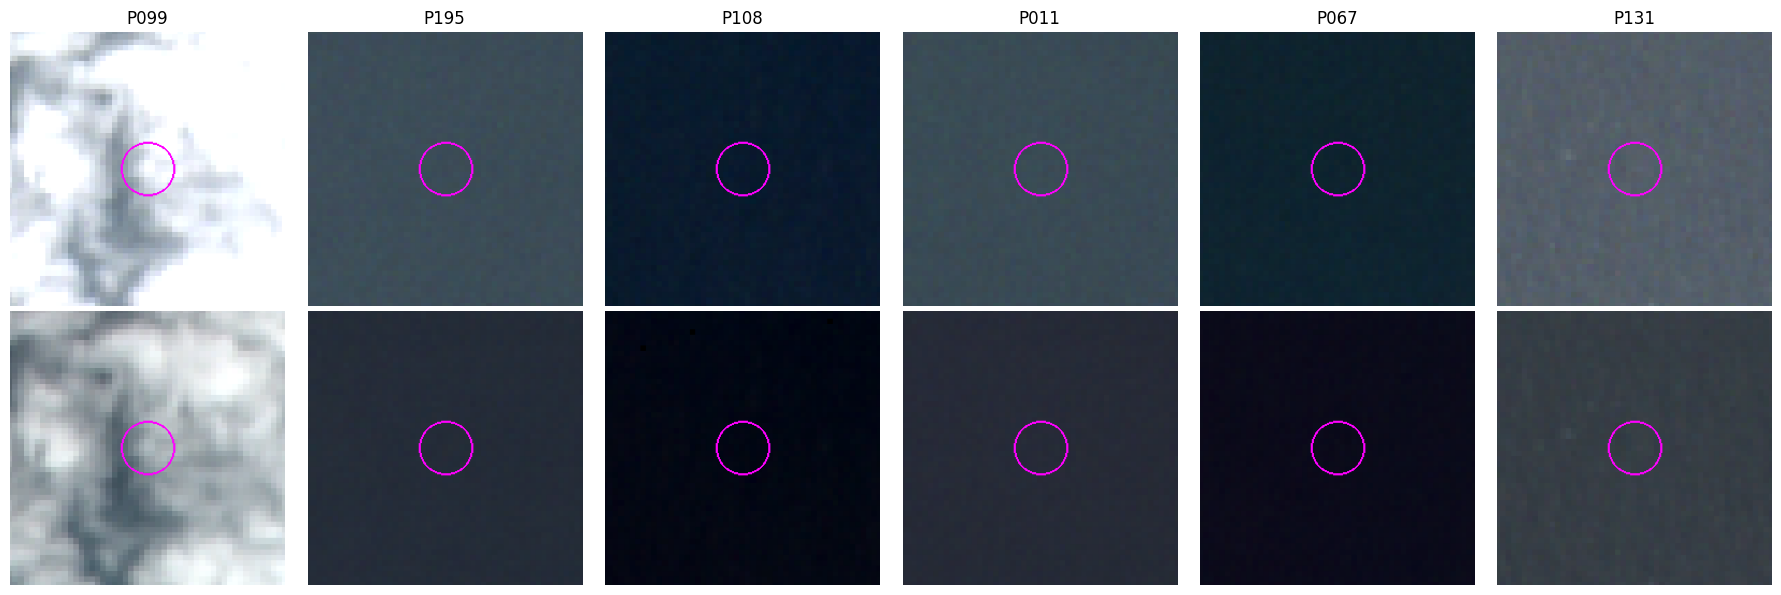

In [16]:
from PIL import Image
import matplotlib.pyplot as plt, glob, random, numpy as np, os
fs = sorted(glob.glob(os.path.join(cf.OUT_DIR, "chips", "*_truecolor.png")))
flat = [os.path.basename(f) for f in fs if np.asarray(Image.open(f)).std() < 2]
print(f"{len(fs)} true-color chips | near-uniform (possible no-data): {flat or 'none'}")
pick = random.Random(0).sample(fs, 6)
fig, ax = plt.subplots(2, 6, figsize=(18, 6))
for i, f in enumerate(pick):
    ax[0, i].imshow(Image.open(f)); ax[1, i].imshow(Image.open(f.replace("truecolor", "falsecolor")))
    ax[0, i].set_title(os.path.basename(f)[:4])
    for a in ax[:, i]: a.axis("off")
plt.tight_layout(); plt.show()

In [17]:
import os, io, csv, datetime as dt, requests, ee
from PIL import Image, ImageDraw
SIZE_M, PX = 1000, 400
TC = dict(bands=["B4", "B3", "B2"], min=0, max=600, gamma=1.2)
FC = dict(bands=["B8", "B4", "B3"], min=0, max=800, gamma=1.2)
OUT = os.path.join(cf.OUT_DIR, "chips_v2"); os.makedirs(OUT, exist_ok=True)

log = cf.load_log()
if not any(x.get("id") == "D4" for x in log.get("deviations", [])):
    log.setdefault("deviations", []).append(dict(
        id="D4", when_utc=dt.datetime.now(dt.timezone.utc).isoformat(),
        what="Chip re-render: 1 km / 400 px nearest-neighbour; water-range stretch TC 0-600, FC 0-800, gamma 1.2; "
             "centre crosshair with gap + 100 m scale bar. Same 200 points, key, IDs and label sheets.",
        why="Protocol stretch (0-2000/0-3000) compressed water to near-black; 500 m chips hid context; ring hid the centre pixel",
        data_seen="QC grid of 6 chips by ID only; key not opened; no labels exist"))
    cf._save_json(cf.LOG_PATH, log)

def render(img, lon, lat, vis, path):
    region = ee.Geometry.Point([lon, lat]).buffer(SIZE_M / 2).bounds()
    url = img.getThumbURL(dict(region=region, dimensions=PX, crs="EPSG:32723", format="png", **vis))
    for k in range(3):
        try:
            im = Image.open(io.BytesIO(requests.get(url, timeout=60).content)).convert("RGB"); break
        except Exception:
            if k == 2: raise
    d, c, g, L = ImageDraw.Draw(im), PX // 2, 8, 22              # gap 8 px (2 S2 pixels), arms 22 px
    for x0, y0, x1, y1 in ((c-g-L, c, c-g, c), (c+g, c, c+g+L, c), (c, c-g-L, c, c-g), (c, c+g, c, c+g+L)):
        d.line([x0, y0, x1, y1], fill=(255, 0, 255), width=2)
    bar = int(100 / SIZE_M * PX)                                  # 100 m scale bar
    d.line([10, PX - 12, 10 + bar, PX - 12], fill=(255, 255, 255), width=3); d.text((10, PX - 28), "100 m", fill=(255, 255, 255))
    im.save(path)

key = list(csv.DictReader(open(os.path.join(cf.OUT_DIR, "KEY_do_not_share_with_labelers", "chip_key.csv"))))
mos = {}
for r in key:
    tc, fc = (os.path.join(OUT, f"{r['chip_id']}_{s}.png") for s in ("truecolor", "falsecolor"))
    if os.path.exists(tc) and os.path.exists(fc): continue
    d = r["s2_date"]
    if d not in mos:
        end = (dt.date.fromisoformat(d) + dt.timedelta(days=1)).isoformat()
        mos[d] = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(core.aoi_ee_geometry()).filterDate(d, end).mosaic()
    render(mos[d], float(r["lon"]), float(r["lat"]), TC, tc)
    render(mos[d], float(r["lon"]), float(r["lat"]), FC, fc)
print(len(os.listdir(OUT)) // 2, "points rendered in", OUT)

200 points rendered in /content/drive/MyDrive/Marine_Plastic_Detection/results/phase3_confirmatory/chips_v2


200 points in chips_v2
false colour | mean brightness (0-255): median 162 | centre minus surroundings: median 0.0, 90th pct 11.2, max 185.0
points whose centre pixel stands out (> 3x local noise): 8 of 200


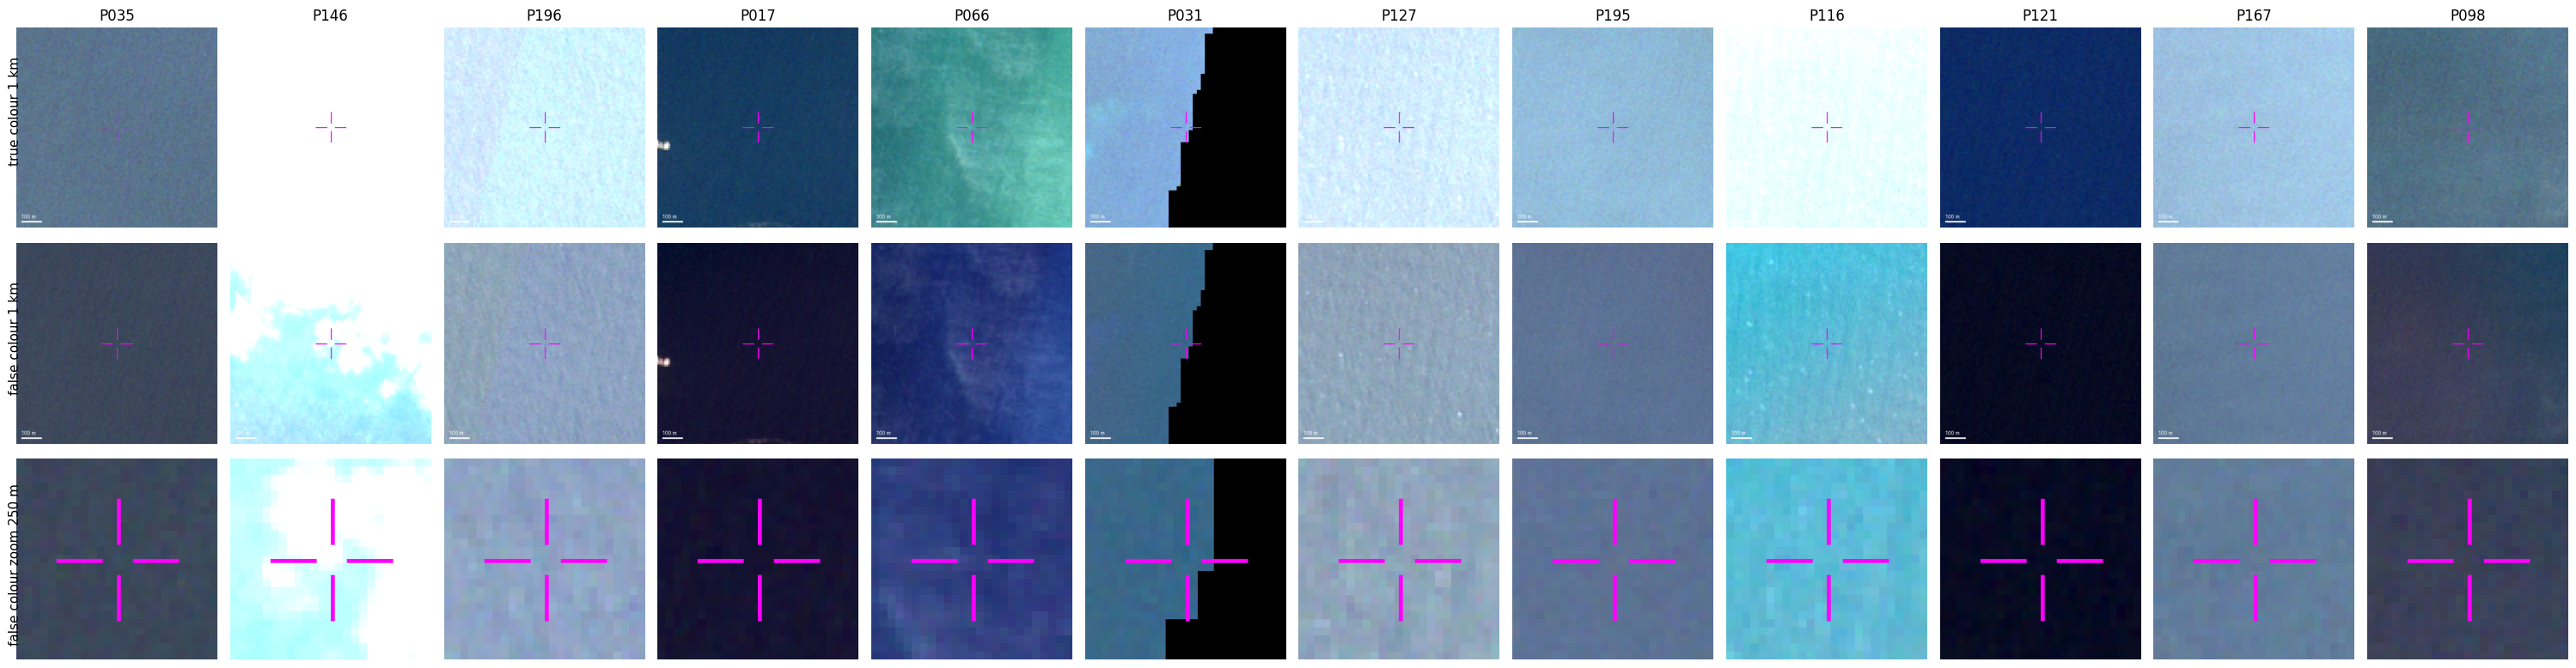

In [18]:
from PIL import Image
import matplotlib.pyplot as plt, glob, random, numpy as np, os
D = os.path.join(cf.OUT_DIR, "chips_v2")
fs = sorted(glob.glob(os.path.join(D, "*_truecolor.png")))
print(len(fs), "points in chips_v2")

# 1) Objective check (no group information): does the centre 10 m pixel stand out from 100-300 m around it?
def centre_stats(path):
    a = np.asarray(Image.open(path).convert("L"), float); c = a.shape[0] // 2
    centre = a[c-2:c+2, c-2:c+2].mean()                       # one S2 pixel = 4x4 screen px, inside the crosshair gap
    yy, xx = np.ogrid[:a.shape[0], :a.shape[1]]; r = np.hypot(yy - c, xx - c)
    ring = a[(r > 40) & (r < 120)]                             # excludes crosshair arms and scale bar
    return centre - np.median(ring), ring.std(), a.mean()
st = np.array([centre_stats(f.replace("truecolor", "falsecolor")) for f in fs])
visible = st[:, 0] > 3 * np.maximum(st[:, 1], 1)
print(f"false colour | mean brightness (0-255): median {np.median(st[:, 2]):.0f} | "
      f"centre minus surroundings: median {np.median(st[:, 0]):.1f}, 90th pct {np.percentile(st[:, 0], 90):.1f}, max {st[:, 0].max():.1f}")
print(f"points whose centre pixel stands out (> 3x local noise): {int(visible.sum())} of {len(fs)}")

# 2) Visual grid: 12 random points — row 1 true colour 1 km, row 2 false colour 1 km, row 3 false-colour zoom 250 m
pick = random.Random(1).sample(fs, 12)
fig, ax = plt.subplots(3, 12, figsize=(30, 8))
for i, f in enumerate(pick):
    tc, fc = Image.open(f), Image.open(f.replace("truecolor", "falsecolor")); c = tc.size[0] // 2
    ax[0, i].imshow(tc); ax[1, i].imshow(fc)
    ax[2, i].imshow(fc.crop((c - 50, c - 50, c + 50, c + 50)).resize((300, 300), Image.NEAREST))
    ax[0, i].set_title(os.path.basename(f)[:4])
    for a in ax[:, i]: a.axis("off")
for r, lab in enumerate(["true colour 1 km", "false colour 1 km", "false colour zoom 250 m"]):
    fig.text(0.002, 0.83 - r * 0.33, lab, rotation=90, va="center", fontsize=11)
plt.tight_layout(); plt.show()

In [19]:
import csv, os, datetime as dt
CLASSES_D5 = ["1 linear or curved feature through/near centre (slick, front, windrow, wake)",
              "2 discrete bright object near centre (vessel, structure, bright speck)",
              "3 rough surface: whitecaps or speckle",
              "4 glint or haze (bright, washed-out water)",
              "5 cloud or cloud shadow near centre",
              "6 image edge / no-data boundary near centre",
              "7 uniform water, nothing visible",
              "8 uncertain"]
log = cf.load_log()
if not any(x.get("id") == "D5" for x in log.get("deviations", [])):
    log.setdefault("deviations", []).append(dict(
        id="D5", when_utc=dt.datetime.now(dt.timezone.utc).isoformat(),
        what="Label classes revised to context conditions (8 classes, incl. image edge/no-data); 'near' = within crosshair arms (~75 m)",
        why="QC grid (chips_v2, IDs only) showed the centre pixel is not visually distinctive at 10 m; context (cloud, glint, "
            "edges, fronts) is judgeable. Original list had no class for image edges.",
        classes=CLASSES_D5, data_seen="QC grid of 12 chips by ID only; key not opened; no labels exist"))
    cf._save_json(cf.LOG_PATH, log)

with open(os.path.join(cf.OUT_DIR, "labeling_instructions.txt"), "w") as f:
    f.write("Use ONLY the folder chips_v2. For each chip_id choose ONE class (1-8) describing what lies at or within the\n"
            "crosshair arms (about 75 m from the centre). Look at both the truecolor and falsecolor chip. If several apply,\n"
            "choose the lowest number. Work independently; do not discuss until both sheets are complete.\n"
            "VHR imagery may be used only to identify persistent fixed structures.\n\n" + "\n".join(CLASSES_D5))
ids = sorted(os.path.basename(p).split("_")[0] for p in os.listdir(os.path.join(cf.OUT_DIR, "chips_v2")) if p.endswith("_truecolor.png"))
for who in ("A", "B"):
    with open(os.path.join(cf.OUT_DIR, f"labels_labeler_{who}.csv"), "w", newline="") as f:
        w = csv.writer(f); w.writerow(["chip_id", "class_1_to_8", "notes"]); w.writerows([[i, "", ""] for i in ids])
print(f"D5 logged | instructions + 2 blank sheets written for {len(ids)} chips")

D5 logged | instructions + 2 blank sheets written for 200 chips


## 6 · Score labels (after both sheets are complete)
Reports Cohen's κ first; then class proportions from the consensus file (if given), candidate vs background, with a permutation χ² test.

In [21]:
import csv, os, json, numpy as np
from scipy import stats
K = 8
CLASSES_D5 = next(x["classes"] for x in cf.load_log()["deviations"] if x["id"] == "D5")
CONSENSUS = None   # step 2: set to os.path.join(cf.OUT_DIR, "labels_consensus.csv")

def read(p):
    txt = open(p, encoding="utf-8-sig").read()
    dialect = csv.Sniffer().sniff(txt.splitlines()[0], delimiters=",;\t")
    out = {}
    for r in csv.DictReader(txt.splitlines(), dialect=dialect):
        v = (r.get("class_1_to_8") or "").strip()
        if v:
            k = int(float(v)); assert 1 <= k <= K, f"{r['chip_id']}: class {k} is outside 1-{K}"
            out[r["chip_id"].strip()] = k
    return out

# ---- Step 1: agreement between labelers (no group information used)
A, B = (read(os.path.join(cf.OUT_DIR, f"labels_labeler_{w}.csv")) for w in ("A", "B"))
if not A or not B:
    raise SystemExit(f"Nothing to score yet: labeler A has {len(A)} labels, labeler B has {len(B)}. "
                     "Fill both sheets (or upload the filled copies to phase3_confirmatory/) and re-run.")
ids = sorted(set(A) & set(B)); a, b = np.array([A[i] for i in ids]), np.array([B[i] for i in ids])
po = float((a == b).mean()); pe = float(sum((a == k).mean() * (b == k).mean() for k in range(1, K + 1)))
kappa = (po - pe) / (1 - pe)
print(f"labeled: A {len(A)}, B {len(B)}, both {len(ids)} of 200 | agreement {po:.1%} | Cohen's kappa {kappa:.3f}")
draft = os.path.join(cf.OUT_DIR, "labels_consensus_draft.csv")
with open(draft, "w", newline="") as f:
    w = csv.writer(f); w.writerow(["chip_id", "class_1_to_8", "notes"])
    for i in ids:
        w.writerow([i, A[i] if A[i] == B[i] else "", "" if A[i] == B[i] else f"A={A[i]} B={B[i]}"])
print(f"{int((a != b).sum())} disagreements left blank in {os.path.basename(draft)}")

# ---- Step 2: candidate vs background (only after the consensus file exists)
if CONSENSUS:
    F = read(CONSENSUS)
    assert len(F) == len(ids), f"consensus has {len(F)} labels; expected {len(ids)} (fill every blank)"
    key = {r["chip_id"]: r["group"] for r in csv.DictReader(open(os.path.join(
        cf.OUT_DIR, "KEY_do_not_share_with_labelers", "chip_key.csv")))}
    tab = np.zeros((2, K), int)
    for cid, k in F.items():
        tab[0 if key[cid] == "candidate" else 1, k - 1] += 1
    prop = {g: {CLASSES_D5[k]: dict(n=int(row[k]), p=float(row[k] / row.sum()),
                                    ci=[float(x) for x in core.wilson(row[k] / row.sum(), int(row.sum()))]) for k in range(K)}
            for g, row in zip(("candidate", "background"), tab)}
    t = tab[:, tab.sum(0) > 0]
    chi2 = float(stats.chi2_contingency(t, correction=False)[0])
    grp = np.repeat([0, 1], t.sum(1)); lab = np.concatenate([np.repeat(np.arange(t.shape[1]), t[i]) for i in range(2)])
    def chi(g):
        m = np.array([[np.sum((g == i) & (lab == j)) for j in range(t.shape[1])] for i in range(2)])
        e = m.sum(1, keepdims=True) * m.sum(0, keepdims=True) / m.sum()
        return float(((m - e) ** 2 / np.where(e > 0, e, 1)).sum())
    rng = np.random.default_rng(cf.CHIP_SEED)
    perm = np.array([chi(rng.permutation(grp)) for _ in range(20_000)])
    p = float((1 + (perm >= chi2 - 1e-9).sum()) / (1 + len(perm)))
    cf._save_json(os.path.join(cf.OUT_DIR, "chip_label_results_D5.json"), dict(
        deviation="D5", n=len(ids), percent_agreement=po, cohen_kappa=kappa, table=tab.tolist(),
        proportions=prop, chi2=chi2, chi2_perm_p=p, permutations=20_000))
    print(f"\n{'class':<70}{'candidate':>12}{'background':>12}")
    for k in range(K):
        print(f"{CLASSES_D5[k]:<70}{tab[0, k]:>12}{tab[1, k]:>12}")
    print(f"chi2 {chi2:.2f}, permutation p {p:.4f} -> saved chip_label_results_D5.json")

SystemExit: Nothing to score yet: labeler A has 0 labels, labeler B has 0. Fill both sheets (or upload the filled copies to phase3_confirmatory/) and re-run.

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [23]:
import os, io, base64, json
from PIL import Image
D = os.path.join(cf.OUT_DIR, "chips_v2")
CLASSES_D5 = next(x["classes"] for x in cf.load_log()["deviations"] if x["id"] == "D5")
ids = sorted(f.split("_")[0] for f in os.listdir(D) if f.endswith("_truecolor.png"))
def b64(p):
    buf = io.BytesIO(); Image.open(p).convert("RGB").save(buf, "JPEG", quality=88)
    return base64.b64encode(buf.getvalue()).decode()
items = [dict(id=i, tc=b64(os.path.join(D, f"{i}_truecolor.png")), fc=b64(os.path.join(D, f"{i}_falsecolor.png"))) for i in ids]

TEMPLATE = r"""<!doctype html><html><head><meta charset="utf-8"><title>Chip labeling - Labeler __W__</title>
<style>body{font-family:system-ui,sans-serif;margin:16px;background:#f4f4f4;color:#222}
.row{display:flex;gap:16px;flex-wrap:wrap}img{width:400px;height:400px;image-rendering:pixelated;border:1px solid #999}
#btns button{display:block;width:100%;text-align:left;margin:4px 0;padding:8px;font-size:14px;border:1px solid #888;border-radius:6px;background:#fff;cursor:pointer}
#btns button.sel{background:#2d6cdf;color:#fff}.bar button{padding:6px 10px}</style></head><body>
<h2>Chip labeling - Labeler __W__ <span id="prog"></span></h2>
<div class="bar"><button id="prev">&#9664; Prev</button> <b id="cid"></b> <button id="next">Next &#9654;</button>
<button id="jump">First unlabeled</button> <button id="exp"><b>Export CSV</b></button></div>
<div class="row"><div>True colour, 1 km<br><img id="tc"></div><div>False colour (NIR), 1 km<br><img id="fc"></div>
<div style="min-width:330px;max-width:420px"><p>Choose ONE class for what lies at the centre or within the crosshair arms (~75 m).
If several apply, choose the <b>lowest</b> number. Keys 1-8 label and move on; arrow keys navigate.</p><div id="btns"></div>
<p>Notes (optional):<br><input id="note" style="width:100%"></p></div></div>
<script>
const W="__W__",DATA=__DATA__,CL=__CLASSES__,KEY="chiplabels_v1_"+W;let S={},i=0;
try{S=JSON.parse(localStorage.getItem(KEY)||"{}")}catch(e){S={}}
const $=id=>document.getElementById(id),save=()=>{try{localStorage.setItem(KEY,JSON.stringify(S))}catch(e){}};
CL.forEach((c,k)=>{const b=document.createElement("button");b.textContent=c;b.onclick=()=>setc(k+1);$("btns").appendChild(b)});
function setc(k){const id=DATA[i].id;S[id]=S[id]||{};S[id].c=k;save();if(i<DATA.length-1)i++;show()}
function show(){const d=DATA[i],cur=(S[d.id]||{}).c;$("cid").textContent=d.id+"  ("+(i+1)+"/"+DATA.length+")";
$("tc").src="data:image/jpeg;base64,"+d.tc;$("fc").src="data:image/jpeg;base64,"+d.fc;
[...$("btns").children].forEach((b,k)=>b.classList.toggle("sel",cur===k+1));$("note").value=(S[d.id]||{}).n||"";
$("prog").textContent=" - "+DATA.filter(x=>(S[x.id]||{}).c).length+" of "+DATA.length+" labeled"}
$("note").oninput=e=>{const id=DATA[i].id;S[id]=S[id]||{};S[id].n=e.target.value;save()};
$("prev").onclick=()=>{if(i>0){i--;show()}};$("next").onclick=()=>{if(i<DATA.length-1){i++;show()}};
$("jump").onclick=()=>{const k=DATA.findIndex(d=>!(S[d.id]||{}).c);if(k>=0){i=k;show()}};
document.addEventListener("keydown",e=>{if(e.target.id==="note")return;const n=parseInt(e.key);
if(n>=1&&n<=8)setc(n);if(e.key==="ArrowLeft")$("prev").click();if(e.key==="ArrowRight")$("next").click()});
$("exp").onclick=()=>{const q=s=>'"'+String(s).replace(/"/g,'""')+'"';
const rows=["chip_id,class_1_to_8,notes"].concat(DATA.map(d=>[d.id,(S[d.id]||{}).c||"",q((S[d.id]||{}).n||"")].join(",")));
const a=document.createElement("a");a.href=URL.createObjectURL(new Blob([rows.join("\n")],{type:"text/csv"}));
a.download="labels_labeler_"+W+".csv";a.click()};show();
</script></body></html>"""
for w in ("A", "B"):
    p = os.path.join(cf.OUT_DIR, f"labeling_tool_{w}.html")
    open(p, "w").write(TEMPLATE.replace("__W__", w).replace("__DATA__", json.dumps(items)).replace("__CLASSES__", json.dumps(CLASSES_D5)))
    print(f"{os.path.basename(p)}: {os.path.getsize(p) / 1e6:.1f} MB, {len(items)} chips")

labeling_tool_A.html: 9.7 MB, 200 chips
labeling_tool_B.html: 9.7 MB, 200 chips


In [24]:
import csv, os, numpy as np
from scipy import stats
K = 8
CLASSES_D5 = next(x["classes"] for x in cf.load_log()["deviations"] if x["id"] == "D5")

def read_labels(p):
    if not os.path.exists(p): return {}
    txt = open(p, encoding="utf-8-sig").read(); lines = txt.splitlines()
    dia = csv.Sniffer().sniff(lines[0], delimiters=",;\t")
    out = {}
    for r in csv.DictReader(lines, dialect=dia):
        v = (r.get("class_1_to_8") or "").strip()
        if v:
            k = int(float(v)); assert 1 <= k <= K, f"{r['chip_id']}: class {k} is outside 1-{K}"
            out[r["chip_id"].strip()] = k
    return out

def score_chips(consensus=None):
    A, B = (read_labels(os.path.join(cf.OUT_DIR, f"labels_labeler_{w}.csv")) for w in ("A", "B"))
    print(f"STATUS  labeler A: {len(A)}/200   labeler B: {len(B)}/200")
    if len(A) < 200 or len(B) < 200:
        print("Not ready: both labelers must finish all 200 chips and their exported CSVs must be in phase3_confirmatory/.")
        return None
    ids = sorted(A); a, b = np.array([A[i] for i in ids]), np.array([B[i] for i in ids])
    po = float((a == b).mean()); pe = float(sum((a == k).mean() * (b == k).mean() for k in range(1, K + 1)))
    kappa = (po - pe) / (1 - pe)
    print(f"STEP 1  agreement {po:.1%} | Cohen's kappa {kappa:.3f} | disagreements {int((a != b).sum())}")
    if consensus is None:
        draft = os.path.join(cf.OUT_DIR, "labels_consensus_draft.csv")
        with open(draft, "w", newline="") as f:
            w = csv.writer(f); w.writerow(["chip_id", "class_1_to_8", "notes"])
            for i in ids:
                w.writerow([i, A[i] if A[i] == B[i] else "", "" if A[i] == B[i] else f"A={A[i]} B={B[i]}"])
        print(f"Next: resolve the blanks in {os.path.basename(draft)}, save as labels_consensus.csv, run score_chips('labels_consensus.csv').")
        return dict(kappa=kappa, agreement=po)
    F = read_labels(os.path.join(cf.OUT_DIR, consensus))
    if len(F) < 200:
        print(f"Consensus file has {len(F)}/200 labels: fill every blank first."); return None
    key = {r["chip_id"]: r["group"] for r in csv.DictReader(open(os.path.join(cf.OUT_DIR, "KEY_do_not_share_with_labelers", "chip_key.csv")))}
    tab = np.zeros((2, K), int)
    for cid, k in F.items(): tab[0 if key[cid] == "candidate" else 1, k - 1] += 1
    t = tab[:, tab.sum(0) > 0]; chi2 = float(stats.chi2_contingency(t, correction=False)[0])
    grp = np.repeat([0, 1], t.sum(1)); lab = np.concatenate([np.repeat(np.arange(t.shape[1]), t[i]) for i in range(2)])
    def chi(g):
        m = np.array([[np.sum((g == i) & (lab == j)) for j in range(t.shape[1])] for i in range(2)])
        e = m.sum(1, keepdims=True) * m.sum(0, keepdims=True) / m.sum(); return float(((m - e) ** 2 / np.where(e > 0, e, 1)).sum())
    rng = np.random.default_rng(cf.CHIP_SEED); perm = np.array([chi(rng.permutation(grp)) for _ in range(20_000)])
    p = float((1 + (perm >= chi2 - 1e-9).sum()) / (1 + len(perm)))
    prop = {g: {CLASSES_D5[k]: dict(n=int(r[k]), p=float(r[k] / 100), ci=[float(x) for x in core.wilson(r[k] / 100, 100)]) for k in range(K)}
            for g, r in zip(("candidate", "background"), tab)}
    cf._save_json(os.path.join(cf.OUT_DIR, "chip_label_results_D5.json"), dict(deviation="D5", percent_agreement=po, cohen_kappa=kappa,
                  table=tab.tolist(), proportions=prop, chi2=chi2, chi2_perm_p=p, permutations=20_000))
    print(f"STEP 2  {'class':<66}{'cand':>6}{'bg':>6}")
    for k in range(K): print(f"        {CLASSES_D5[k]:<66}{tab[0, k]:>6}{tab[1, k]:>6}")
    print(f"        chi2 {chi2:.2f}, permutation p {p:.4f}  -> chip_label_results_D5.json")

score_chips()

STATUS  labeler A: 0/200   labeler B: 0/200
Not ready: both labelers must finish all 200 chips and their exported CSVs must be in phase3_confirmatory/.


In [25]:
import datetime as dt, gc, os, numpy as np
log = cf.load_log()
if not any(x.get("id") == "D6" for x in log.get("deviations", [])):
    log["deviations"].append(dict(
        id="D6", when_utc=dt.datetime.now(dt.timezone.utc).isoformat(),
        what="Protocol §5 (blind visual labeling) not performed. Replaced by objective context shares: fraction of "
             "top-1% FDI candidates vs all SCL-water pixels within 100 m of land / cloud / other / no-data, per date, "
             "whole scene and open water (>=500 m from land).",
        why="Only one person available; QC of chips_v2 (IDs only) showed the centre pixel is not visually distinctive at 10 m",
        data_seen="no labels exist; key never opened"))
    cf._save_json(cf.LOG_PATH, log)

NEAR, CL = 100.0, ("land", "cloud", "other", "nodata")
DATES = [p[0] for p in core.DATE_PAIRS] + sorted(d for d, r in log["dates"].items() if r["status"] == "confirmed")
out = {}
for d in DATES:
    cf.mem_guard(f"context {d}")
    R = core.get_s2_raster(d); w = core.water_mask(R)
    f = core.fdi_from_dn(R["B6"], R["B8"], R["B11"], core.FDI_W_OURS)
    cand = w & (f >= np.percentile(f[w], 99)); del f
    dm = core.class_distance_maps(R); del R; gc.collect()
    ow = dm["land"] >= core.OPEN_WATER_MIN_DIST_M
    res = {}
    for name, m in (("cand", cand), ("water", w), ("cand_ow", cand & ow), ("water_ow", w & ow)):
        dmin = np.minimum.reduce([dm[c][m] for c in CL])
        res[name] = dict(n=int(m.sum()), any=float((dmin <= NEAR).mean()),
                         **{c: float((dm[c][m] <= NEAR).mean()) for c in CL})
        del dmin
    out[d] = res; del dm, w, cand, ow; gc.collect()
    c, wa, co, wo = res["cand"], res["water"], res["cand_ow"], res["water_ow"]
    print(f"{d} | within 100 m of any non-water: cand {c['any']:.0%} vs water {wa['any']:.0%} | "
          f"open water: cand {co['any']:.0%} vs water {wo['any']:.0%} "
          f"(cloud {co['cloud']:.0%}/{wo['cloud']:.0%}, no-data {co['nodata']:.0%}/{wo['nodata']:.0%})")
cf._save_json(os.path.join(cf.OUT_DIR, "D6_context_shares.json"), dict(deviation="D6", near_m=NEAR, per_date=out))
print("saved D6_context_shares.json")

[01:34:55] [mem] 10% RAM, 12.3 GB free — context 2024-09-09
[01:34:57] [S2-RASTER] cache hit /content/drive/MyDrive/Marine_Plastic_Detection/cache/s2_raster_2024-09-09.npz ((5210, 6367))
2024-09-09 | within 100 m of any non-water: cand 57% vs water 9% | open water: cand 33% vs water 7% (cloud 32%/6%, no-data 1%/1%)
[01:35:18] [mem] 11% RAM, 12.1 GB free — context 2024-09-14
[01:35:19] [S2-RASTER] cache hit /content/drive/MyDrive/Marine_Plastic_Detection/cache/s2_raster_2024-09-14.npz ((5210, 6367))
2024-09-14 | within 100 m of any non-water: cand 60% vs water 8% | open water: cand 19% vs water 4% (cloud 18%/3%, no-data 0%/1%)
[01:35:37] [mem] 10% RAM, 12.3 GB free — context 2024-08-08
[01:35:37] [S2-RASTER] cache hit /content/drive/MyDrive/Marine_Plastic_Detection/cache/s2_raster_2024-08-08.npz ((5210, 6367))
2024-08-08 | within 100 m of any non-water: cand 38% vs water 5% | open water: cand 1% vs water 1% (cloud 1%/0%, no-data 0%/1%)
[01:35:52] [mem] 12% RAM, 12.0 GB free — context 20